# 1. Imports & Setup

In [1]:
# imports
import json, random
from pathlib import Path

import numpy as np
import pandas as pd

from torch import nn
import torch, torchvision
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from torchvision.models import resnet18, ResNet18_Weights

from datasets import load_dataset
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import GroupShuffleSplit

# Project utilities
from baseline_utils import (
    get_leaf_groups,
    plot_class_distributions,
    train_model,
    plot_training_history,
    export_test_predictions
)

# seed
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

# device settings
if torch.cuda.is_available():
    device_id = torch.cuda.current_device()
    device = torch.device('cuda:%d' % device_id)
    print(torch.cuda.get_device_name(device_id))
else:
    device = torch.device('cpu')

NVIDIA GeForce RTX 4060 Ti


# 2. Load Dataset, Split & Investigate

In [2]:
dataset = load_dataset("geraldmc/plantvillage-full")

data = dataset["train"]

train_dataset = data.filter(lambda x: x["split"] == "train")
test_dataset = data.filter(lambda x: x["split"] == "test")

In [3]:
# get validation split

# Construct group identifiers
groups = [
    f"leaf:{row['host']}:{row['disease']}:{row['leaf_id']}"
    if row["leaf_grouped"] and row["leaf_id"] is not None
    else f"unique:{i}"
    for i, row in enumerate(train_dataset)
]

# Split 12.5% of groups into validation
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.125,
    random_state=42
)

train_idx, val_idx = next(
    splitter.split(train_dataset, groups=groups)
)

val_dataset = train_dataset.select(val_idx)
train_dataset = train_dataset.select(train_idx)

nSamplesOverall = len(train_dataset) + len(val_dataset) + len(test_dataset)

print(f"Train:\n Samples: {len(train_dataset)}, %: {len(train_dataset) / nSamplesOverall * 100:.2f}%")
print(f"Validation:\n Samples: {len(val_dataset)}, %: {len(val_dataset) / nSamplesOverall * 100:.2f}%")
print(f"Test:\n Samples: {len(test_dataset)}, %: {len(test_dataset) / nSamplesOverall * 100:.2f}%")

Train:
 Samples: 38161, %: 70.27%
Validation:
 Samples: 5195, %: 9.57%
Test:
 Samples: 10948, %: 20.16%


In [4]:
# check for leakage
train_groups = get_leaf_groups(train_dataset)
val_groups = get_leaf_groups(val_dataset)
test_groups = get_leaf_groups(test_dataset)

print("Train / Val overlap:", len(train_groups & val_groups))
print("Train / Test overlap:", len(train_groups & test_groups))
print("Val / Test overlap:", len(val_groups & test_groups))

Train / Val overlap: 0
Train / Test overlap: 0
Val / Test overlap: 0


In [5]:
# check class balance 
train_counts = pd.Series(train_dataset["class_label"]).value_counts()
val_counts = pd.Series(val_dataset["class_label"]).value_counts()
test_counts = pd.Series(test_dataset["class_label"]).value_counts()

class_counts = pd.DataFrame({
    "Train": train_counts,
    "Validation": val_counts,
    "Test": test_counts
}).fillna(0).astype(int).sort_index()

class_counts["Total"] = class_counts.sum(axis=1)

print("Number of classes:", len(class_counts))

display(class_counts)

Number of classes: 38


,Train,Validation,Test,Total
Apple___Apple_scab,451,56,123,630
Apple___Black_rot,433,64,124,621
Apple___Cedar_apple_rust,184,36,55,275
Apple___healthy,1168,153,324,1645
Blueberry___healthy,1089,135,278,1502
Cherry_(including_sour)___Powdery_mildew,690,110,252,1052
Cherry_(including_sour)___healthy,615,60,179,854
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot,362,48,103,513
Corn_(maize)___Common_rust_,831,123,238,1192
Corn_(maize)___Northern_Leaf_Blight,687,101,197,985


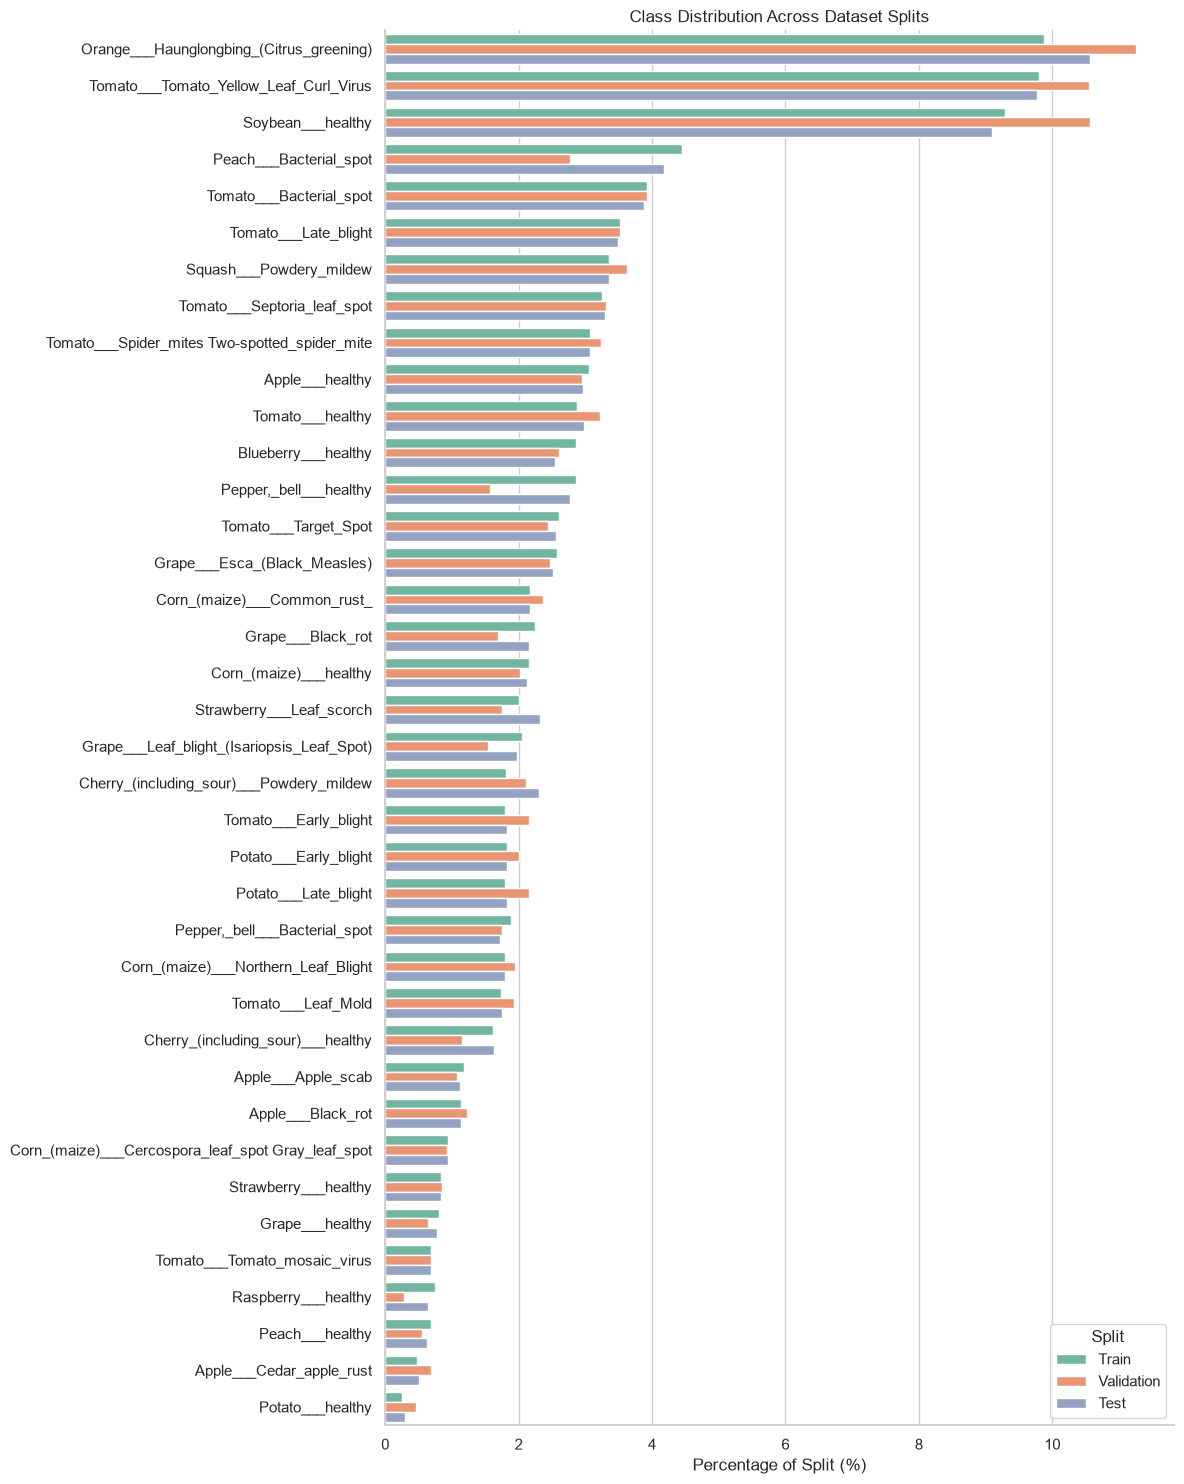

In [6]:
# Enable visualizations when needed
plot_class_distributions(class_counts, barplot=True, heatmap=False, difference_heatmap=True)

# 3. Model Setup & Image Preprocessing

In [7]:
IMG_SIZE = 224

# ImageNet normalization
mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std)
])

eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std)
])

In [8]:
# Load pretrained ResNet18
model = resnet18(weights=ResNet18_Weights.DEFAULT)

# Adapt classification head for PlantVillage
NUM_CLASSES = 38

model.fc = nn.Linear(
    model.fc.in_features,
    NUM_CLASSES
)

# Move model to device
model = model.to(device)

print("Model:", model.__class__.__name__)
print("Output classes:", model.fc.out_features)

Model: ResNet
Output classes: 38


# 4. Pytorch Dataset & Dataloaders

In [9]:
class PlantVillageDataset(Dataset):
    def __init__(self, dataset, transform=None):
        self.dataset = dataset
        self.transform = transform

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):
        sample = self.dataset[idx]

        image = sample["image"].convert("RGB")
        label = int(sample["class_idx"])

        if self.transform:
            image = self.transform(image)

        return image, label

In [10]:
# apply transforms
train_torch = PlantVillageDataset(
    train_dataset,
    transform=train_transform
)

val_torch = PlantVillageDataset(
    val_dataset,
    transform=eval_transform
)

test_torch = PlantVillageDataset(
    test_dataset,
    transform=eval_transform
)

In [11]:
# create dataloaders
BATCH_SIZE = 32
NUM_WORKERS = 0

train_loader = DataLoader(
    train_torch,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=(device.type == "cuda")
)

val_loader = DataLoader(
    val_torch,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(device.type == "cuda")
)

test_loader = DataLoader(
    test_torch,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(device.type == "cuda")
)

# 5. Model training / fine tuning

In [12]:
# Training configuration
EPOCHS = 10
LEARNING_RATE = 1e-4
PATIENCE = 3
MIN_DELTA = 0.001

# Output directory
OUTPUT_DIR = Path("outputs/resnet18")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

In [13]:
# start training
history = train_model(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer,
    device=device,
    epochs=EPOCHS,
    patience=PATIENCE,
    min_delta=MIN_DELTA,
    output_dir=OUTPUT_DIR
)

Training:   0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01/10 | Train Loss: 0.2260 | Train Acc: 94.67% | Val Loss: 0.0577 | Val Acc: 98.40%
Epoch 02/10 | Train Loss: 0.0479 | Train Acc: 98.62% | Val Loss: 0.0387 | Val Acc: 98.86%
Epoch 03/10 | Train Loss: 0.0355 | Train Acc: 98.94% | Val Loss: 0.0481 | Val Acc: 98.59%
Epoch 04/10 | Train Loss: 0.0312 | Train Acc: 99.05% | Val Loss: 0.0418 | Val Acc: 98.83%
Epoch 05/10 | Train Loss: 0.0232 | Train Acc: 99.33% | Val Loss: 0.0308 | Val Acc: 99.10%
Epoch 06/10 | Train Loss: 0.0213 | Train Acc: 99.38% | Val Loss: 0.0308 | Val Acc: 99.00%
Epoch 07/10 | Train Loss: 0.0231 | Train Acc: 99.23% | Val Loss: 0.0341 | Val Acc: 98.86%
Epoch 08/10 | Train Loss: 0.0165 | Train Acc: 99.46% | Val Loss: 0.0354 | Val Acc: 99.10%

Early stopping at epoch 8

Best epoch: 5
Best validation loss: 0.0308


In [15]:
# Locate existing checkpoint
OUTPUT_DIR = Path("outputs/resnet18")
BEST_CHECKPOINT = OUTPUT_DIR / "best_model.pth"

# Load trained weights
checkpoint = torch.load(
    BEST_CHECKPOINT,
    map_location=device,
    weights_only=True
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print(f"Best epoch: {checkpoint['epoch']}")
print(f"Validation loss: {checkpoint['val_loss']:.4f}")
print(f"Validation accuracy: {checkpoint['val_acc']:.2%}")

Best epoch: 5
Validation loss: 0.0308
Validation accuracy: 99.10%


# 6. Exports and Short Eval

In [16]:
# export test predictions

# prepare mapping for human-readable labels
class_mapping = (
    pd.DataFrame({
        "class_idx": train_dataset["class_idx"],
        "class_label": train_dataset["class_label"]
    })
    .drop_duplicates()
    .set_index("class_idx")["class_label"]
    .to_dict()
)

test_predictions = export_test_predictions(
    model=model,
    loader=test_loader,
    dataset=test_dataset,
    device=device,
    output_path=OUTPUT_DIR / "test_predictions.csv"
)

# Add human-readable predicted labels
test_predictions["pred_label"] = (
    test_predictions["pred_idx"].map(class_mapping)
)

test_predictions.to_csv(
    OUTPUT_DIR / "test_predictions.csv",
    index=False
)

print(f"Exported {len(test_predictions)} test predictions.")

Test inference:   0%|          | 0/343 [00:00<?, ?it/s]

Saved 10948 predictions to outputs\resnet18\test_predictions.csv
Test accuracy: 99.02%
Exported 10948 test predictions.


In [17]:
# basic test eval
y_true = test_predictions["true_idx"]
y_pred = test_predictions["pred_idx"]

accuracy = accuracy_score(y_true, y_pred)
macro_f1 = f1_score(y_true, y_pred, average="macro", zero_division=0)

print(f"Test Accuracy: {accuracy:.4%}")
print(f"Test Macro F1: {macro_f1:.4%}")

Test Accuracy: 99.0227%
Test Macro F1: 98.8251%
